In [82]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import Dense,Input,SimpleRNN,Embedding
from tensorflow.keras.models import Sequential
from tensorflow.keras.metrics import Accuracy

In [83]:
df = pd.read_csv('/content/SMS SPAM.zip', encoding='latin-1')

In [84]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [85]:
df = df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [86]:
le = LabelEncoder()
df['v1'] = le.fit_transform(df['v1'])
df.head()

,v1,v2
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [87]:
df.value_counts('v1')

,count
v1,
0,4825
1,747


In [88]:
x = df['v2']
y = df['v1']

In [89]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42
)

In [90]:
print(y_train.unique())

[0 1]


In [91]:
vocab_size = 5000

tokenizer = Tokenizer(num_words=vocab_size)

tokenizer.fit_on_texts(x_train)

In [92]:
x_train = tokenizer.texts_to_sequences(x_train)
x_test = tokenizer.texts_to_sequences(x_test)

In [93]:
max_len = 50

x_train = keras.preprocessing.sequence.pad_sequences(
    x_train,
    maxlen = max_len,
    padding = "post",
    truncating = "post"
)

x_test = keras.preprocessing.sequence.pad_sequences(
    x_test,
    maxlen = max_len,
    padding = "post",
    truncating = "post"
)


In [94]:
print(x_train.shape)
print(x_test.shape)

(4457, 50)
(1115, 50)


In [95]:
len(x_train[0])
len(x_test[0])

50

In [101]:
print(y_train.unique())

[0 1]


In [96]:
model = Sequential([Input(shape=(max_len,)),
                    Embedding(
                        input_dim = vocab_size,
                        output_dim = 32
                    ),
                    SimpleRNN(
                        units = 32,
                        activation = 'tanh'
                    ),
                    Dense(
                        units = 1,
                        activation = 'sigmoid'
                    )
])

In [97]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,113 (633.25 KB)

 Trainable params: 162,113 (633.25 KB)

 Non-trainable params: 0 (0.00 B)

In [98]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['Accuracy'])

In [106]:
history = model.fit(x_train,y_train,epochs=5,batch_size=8,validation_split=0.1,verbose=1)

Epoch 1/5
502/502 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - Accuracy: 0.9995 - loss: 0.0035 - val_Accuracy: 0.9103 - val_loss: 0.5197
Epoch 2/5
502/502 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.9833 - loss: 0.0584 - val_Accuracy: 0.8767 - val_loss: 0.3954
Epoch 3/5
502/502 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - Accuracy: 0.9511 - loss: 0.1578 - val_Accuracy: 0.8565 - val_loss: 0.4033
Epoch 4/5
502/502 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.8811 - loss: 0.3315 - val_Accuracy: 0.8610 - val_loss: 0.3582
Epoch 5/5
502/502 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - Accuracy: 0.9529 - loss: 0.1420 - val_Accuracy: 0.8475 - val_loss: 0.4070


In [107]:
loss,Accuracy = model.evaluate(x_test,y_test)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Accuracy: 0.8726 - loss: 0.3546


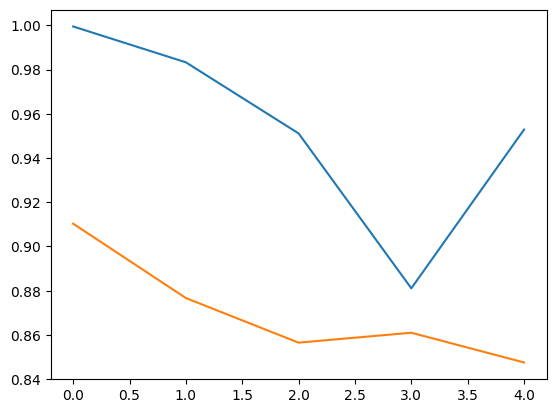

In [108]:
plt.plot(history.history['Accuracy'], label='Training Accuracy')
plt.plot(history.history['val_Accuracy'], label='Validation Accuracy')

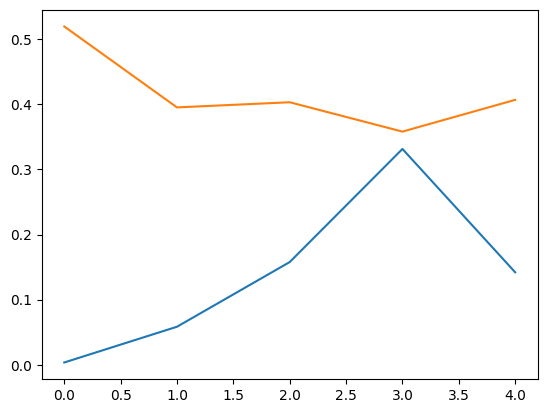

In [109]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')